# Comparing BFS and A* Search

# Code

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np
import maze_helper as mh

#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
f = open("L_maze.txt", "r")

maze_str = f.read()
maze = mh.parse_maze(maze_str)

In [2]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts


# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)

## BFS

Breadth-first search is an _optimal_ algorithm. BFS is an _uninformed search algorithm and has no idea where the goal is. It expands the search in concentric circles around the start till it hits the goal.

In [3]:
%time result = ts.best_first_search(maze, strategy = "BFS", debug = False, vis = False, animation = True)

ts.animate_maze(result)

CPU times: user 2.08 ms, sys: 0 ns, total: 2.08 ms
Wall time: 2.08 ms
Path length: 16
Reached squares: 151
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'E']


Note that BFS explores almost the whole maze. BFS keeps the whole tree (notes are represented by gray squares) in memory. This is a problem for many AI problems with large state spaces. 

## A* Search - Euclidean Heuristic

A* Search is an _informed_ search algorithms. It gets information about where the goal is using the heuristic function. The value of the heuristic function tends to decrease the closer we get to the goal. It is optimal if A* is an admissible heuristic.

In [4]:
# set heuristic for my A* search implementation
#ts.heuristic = ts.manhattan
ts.heuristic = ts.euclidean

%time result = ts.best_first_search(maze, strategy = "A*", debug = False, vis = False, animation = True)
ts.animate_maze(result)

CPU times: user 908 μs, sys: 73 μs, total: 981 μs
Wall time: 985 μs
Path length: 16
Reached squares: 62
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'E', 'N']


## A* Search - Manhattan Heuristic

In [5]:
# set heuristic for my A* search implementation
ts.heuristic = ts.manhattan
#ts.heuristic = ts.euclidean

%time result = ts.best_first_search(maze, strategy = "A*", debug = False, vis = False, animation = True)
ts.animate_maze(result)

CPU times: user 738 μs, sys: 44 μs, total: 782 μs
Wall time: 785 μs
Path length: 16
Reached squares: 40
Action sequence: ['E', 'E', 'E', 'E', 'S', 'E', 'E', 'E', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


## Comparison

* BFS and A* search are both optimal and find the shortest possible path.
* BFS explores 142 states and needs to store a tree of that size, while A* explores significantly less.
* The effectiveness of A* depends on how good the heuristic is. Manhatten distance is a very good heuristic for this problem.
* For some AI problems, the smaller tree that A* creates may still be too large for the available memory. Here other methods weighted A* search or, iterative deepening search may need to be used. 

---
# BÀI 5 — PHẦN SO SÁNH TRỰC TIẾP BFS VÀ A* (BỔ SUNG)

Các cell phía trên là nội dung **nguyên bản** của notebook `04_Maze_BFS_vs_A_Star.ipynb`. Đoạn nhận xét gốc có nêu ví dụ số trạng thái mở rộng của BFS bằng 142; đó là nhận xét trong tài liệu tác giả, không được xem là kết quả đo từ mã triển khai hỗ trợ hiện tại. Phần thực nghiệm tiếp theo **tính lại** mọi chỉ số trên file dữ liệu thật bằng phiên bản `tree_search_solution.py` đi kèm.

Thiết lập so sánh: `small_maze`, `medium_maze`, `L_maze` và `open_maze`; di chuyển 4 hướng với chi phí 1; thứ tự mở rộng cố định `NESW`. Định nghĩa nút mở rộng: trạng thái được chọn từ frontier và sinh các trạng thái kế tiếp, không tính lần lấy đích ra.

## 5.6. Công thức heuristic

Cho trạng thái hiện tại $n=(r_n,c_n)$ và đích $G=(r_g,c_g)$:

$$h_\mathrm{Manhattan}(n)=|r_n-r_g|+|c_n-c_g|$$

$$h_\mathrm{Euclidean}(n)=\sqrt{(r_n-r_g)^2+(c_n-c_g)^2}$$

A* dùng $f(n)=g(n)+h(n)$. Manhattan bằng đúng độ dài tối thiểu nếu lưới hoàn toàn không có tường và chỉ được di chuyển bốn hướng. Euclidean là khoảng cách đường thẳng, vì thế cũng không ước lượng quá chi phí thực tế nhưng thông tin định hướng thường yếu hơn Manhattan.

In [6]:
import math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import maze_helper as mh
import tree_search_solution as ts
from IPython.display import display
from matplotlib.colors import ListedColormap

# Hàm dựa đúng trên phép toán của đề; tránh phụ thuộc thứ tự chạy các cell phía trước.
def euclidean_bai5(p, g):
    return math.hypot(p[0] - g[0], p[1] - g[1])
def manhattan_bai5(p, g):
    return abs(p[0] - g[0]) + abs(p[1] - g[1])

def read_maze_bai5(name):
    with open(f'{name}_maze.txt', encoding='utf-8') as f:
        return mh.parse_maze(f.read())

def bench_bai5(maze, algorithm, h='Manhattan'):
    ts.set_order('NESW')
    ts.heuristic = euclidean_bai5 if h == 'Euclidean' else manhattan_bai5
    tic = time.perf_counter()
    result = ts.best_first_search(maze, strategy=algorithm, W=1.0, animation=False)
    return result, round((time.perf_counter() - tic)*1000, 4)

assert euclidean_bai5((0,0), (3,4)) == 5.0
assert manhattan_bai5((0,0), (3,4)) == 7

## 5.7. Chạy BFS, A* Euclidean và A* Manhattan

Dùng cùng mê cung và quy tắc chọn nút. Mỗi kết quả ghi: độ dài đường đi, số nút mở rộng, max frontier và thời gian thực thi; cần phân biệt **thời gian Python** với **số nút mở rộng**.

In [7]:
compare_bfs_astar_bai5 = []
results_by_maze_bai5 = {}
for name in ('small', 'medium', 'L', 'open'):
    maze_case = read_maze_bai5(name)
    results_by_maze_bai5[name] = {}
    for label, alg, heur in [
        ('BFS', 'BFS', 'Manhattan'),
        ('A* Euclidean', 'A*', 'Euclidean'),
        ('A* Manhattan', 'A*', 'Manhattan'),
    ]:
        result, ms = bench_bai5(maze_case, alg, heur)
        results_by_maze_bai5[name][label] = result
        compare_bfs_astar_bai5.append({
            'Mê cung':name, 'Thuật toán':label,
            'Path cost':result['path_cost'], 'Nút mở rộng':result['n_expanded'],
            'Max frontier':result['max_frontier'], 'Thời gian (ms)':ms
        })
bfs_astar_bai5 = pd.DataFrame(compare_bfs_astar_bai5)
display(bfs_astar_bai5)
for name, block in bfs_astar_bai5.groupby('Mê cung'):
    assert block['Path cost'].nunique()==1, f'A* không trùng BFS: {name}'

,Mê cung,Thuật toán,Path cost,Nút mở rộng,Max frontier,Thời gian (ms)
0,small,BFS,19,92,9,0.6572
1,small,A* Euclidean,19,55,7,0.4180
2,small,A* Manhattan,19,51,7,0.3774
3,medium,BFS,68,269,9,1.4391
4,medium,A* Euclidean,68,224,8,1.2334
5,medium,A* Manhattan,68,217,8,1.6969
6,L,BFS,16,151,17,0.7299
7,L,A* Euclidean,16,62,27,0.4082
8,L,A* Manhattan,16,40,29,0.4286
9,open,BFS,54,682,25,3.7851


## 5.8. Trực quan vùng mở rộng và đường đi

Trong hình dưới đây, nền đậm là tường, phần đường màu cam là đường tìm được, dấu đánh dấu là điểm bắt đầu/đích, các ô xanh nhạt là trạng thái đã được mở rộng. Các ô màu xanh không nhất thiết thuộc đường đi cuối cùng.

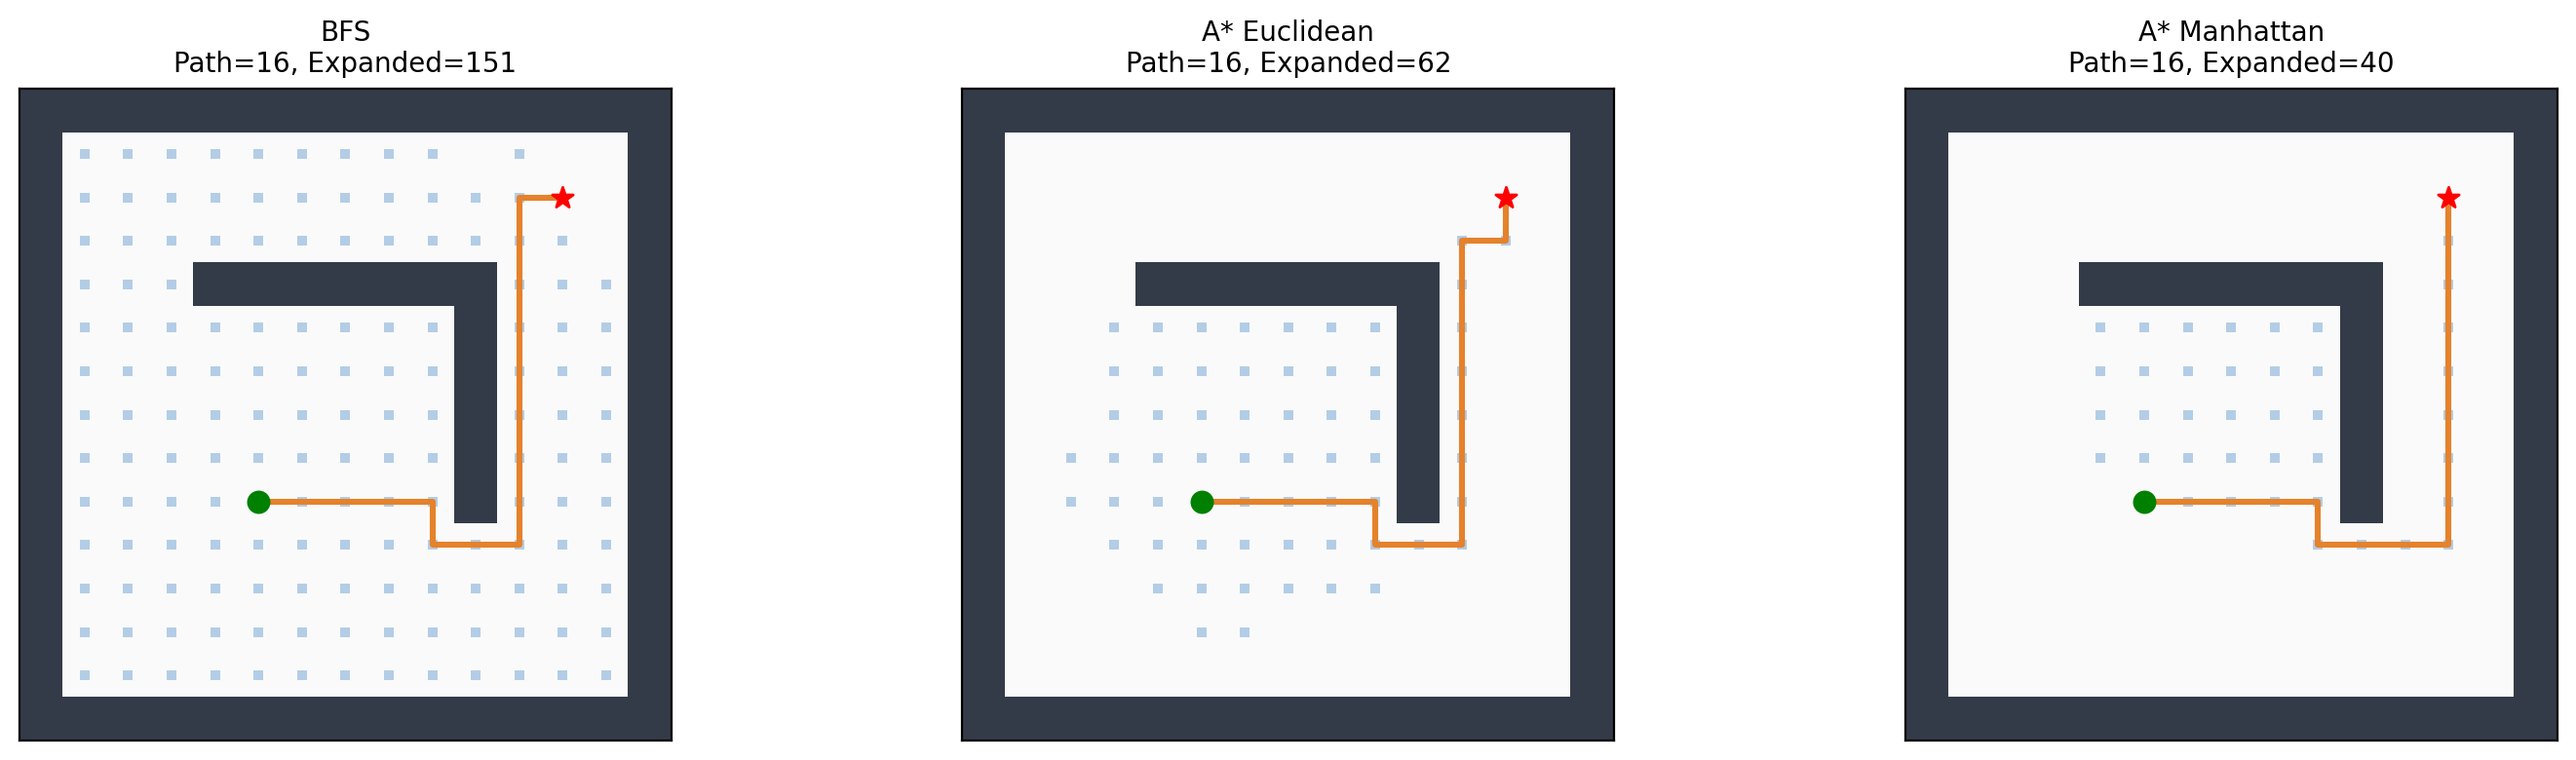

In [8]:
def draw_result_bai5(ax, maze, result, title):
    ax.imshow((maze!='X').astype(int), cmap=ListedColormap(['#343b48','#fafafa']), vmin=0, vmax=1)
    for r,c in result['reached']:
        if maze[r,c] == ' ':
            ax.scatter(c,r,s=15,c='#7aa9d9',alpha=.55,marker='s',linewidths=0)
    if result['path']:
        ax.plot([p[1] for p in result['path']], [p[0] for p in result['path']], color='#e5822b',linewidth=2.2)
    s,g=mh.find_pos(maze,'S'),mh.find_pos(maze,'G')
    ax.scatter(s[1],s[0],s=58,c='green',zorder=5)
    ax.scatter(g[1],g[0],s=65,c='red',marker='*',zorder=5)
    ax.set_xticks([]);ax.set_yticks([]);ax.set_title(title,fontsize=10)

name='L'
maze_l_bai5=read_maze_bai5(name)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,label in zip(axes,['BFS','A* Euclidean','A* Manhattan']):
    res=results_by_maze_bai5[name][label]
    draw_result_bai5(ax,maze_l_bai5,res,f'{label}\nPath={res["path_cost"]}, Expanded={res["n_expanded"]}')
plt.tight_layout();plt.show()

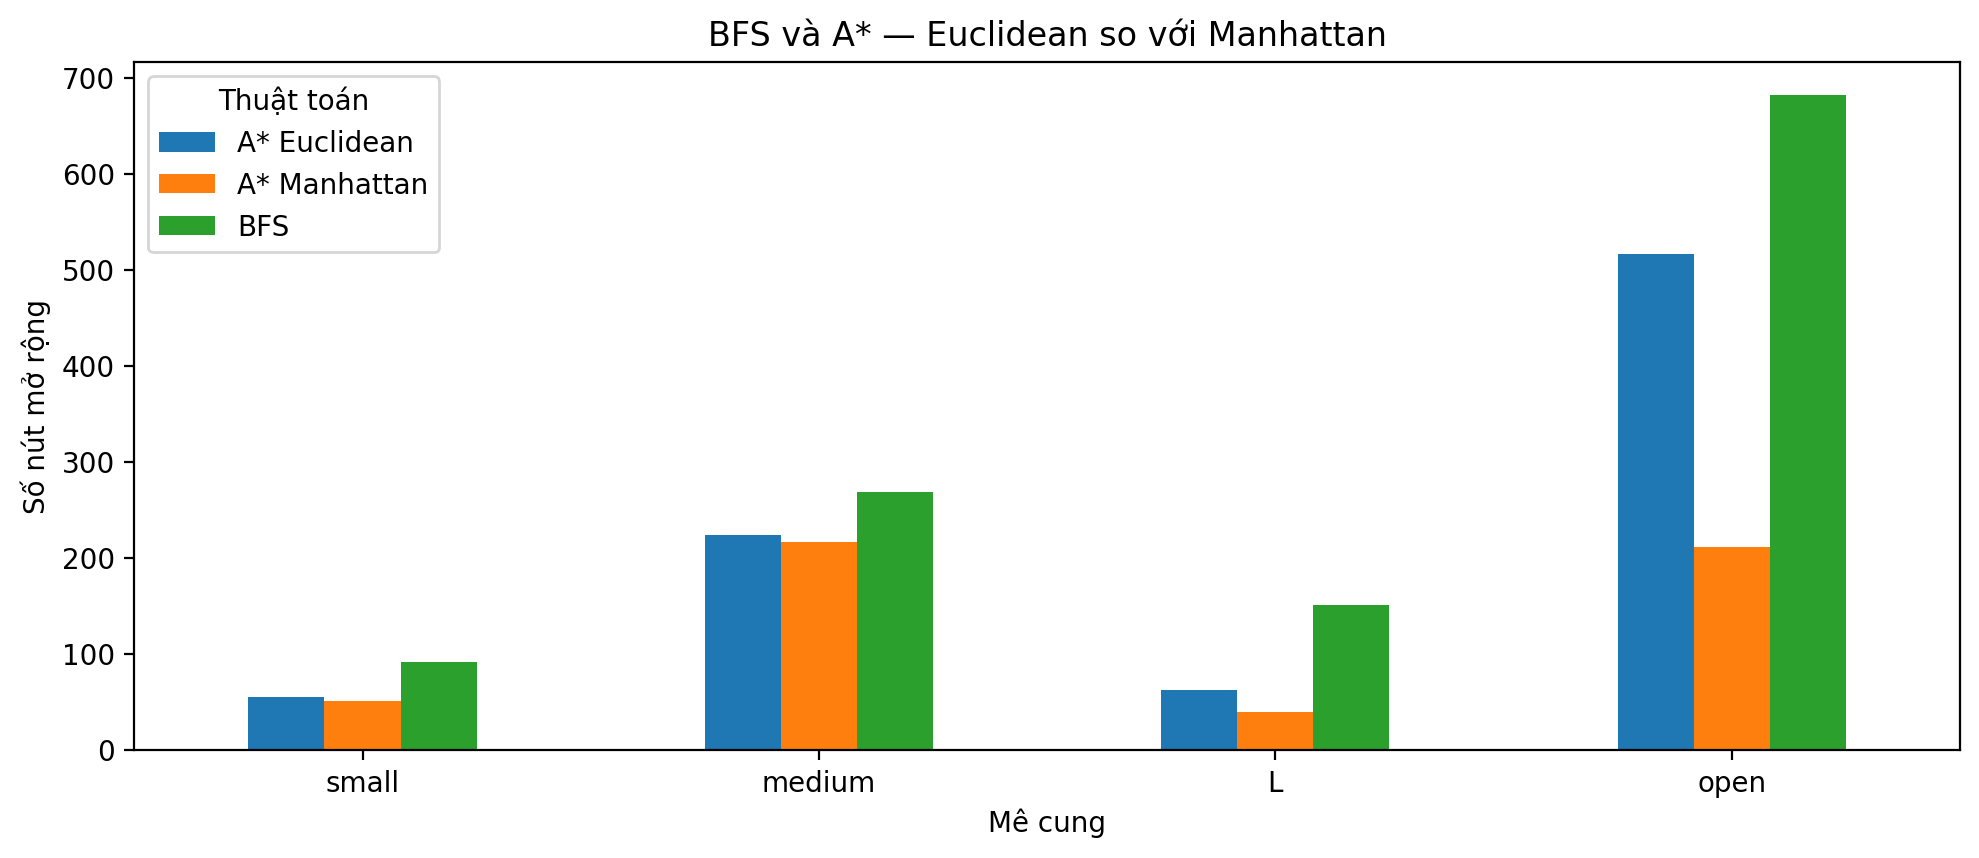

In [9]:
# Biểu đồ so sánh số nút mở rộng trên 4 mê cung
wide_bai5=bfs_astar_bai5.pivot(index='Mê cung',columns='Thuật toán',values='Nút mở rộng')
ax=wide_bai5.reindex(['small','medium','L','open']).plot(kind='bar',figsize=(10,4.4),rot=0)
ax.set(ylabel='Số nút mở rộng',title='BFS và A* — Euclidean so với Manhattan')
plt.tight_layout();plt.show()

## 5.9. Kết luận đối chiếu BFS và A*

**BFS** không sử dụng thông tin vị trí của đích và tìm đường ngắn nhất với chi phí bước đồng đều. **A*** bổ sung ước lượng $h(n)$ để ưu tiên mở rộng những trạng thái có tổng chi phí ước lượng nhỏ hơn. Trong thí nghiệm, BFS và A* (Euclidean, Manhattan) đều tìm được chi phí đường đi ngắn nhất; tuy nhiên hiệu quả giảm số nút mở rộng không phải lúc nào cũng như nhau trên mọi mê cung.

Manhattan thường thể hiện ưu thế trên lưới bốn hướng vì phản ánh trực tiếp số bước ngang và dọc ít nhất để tới đích khi bỏ qua tường. Nhờ đó, A* thường thu hẹp vùng cần khảo sát so với BFS. Euclidean vẫn bảo đảm không đánh giá quá chi phí thực khi mỗi bước tốn 1 nhưng thường kém định hướng hơn Manhattan.

**Lưu ý:** Số liệu quan sát từ mã học tập bổ sung có thể khác con số mô tả trong notebook gốc của tác giả do khác cài đặt, tie-breaking và cách đếm trạng thái đã mở rộng. Kết luận lý thuyết không phụ thuộc những con số minh họa riêng lẻ.